# Synthetic biomarker benchmark — PVBM and OCULAR

This notebook is one of three, one per **lineage** of biomarker software, beside a
[summary notebook](biomarker-synthetic.ipynb) that compares the three over the catalogue's own
names. It reads the evidence of one run of the benchmark and argues about what it shows for this
group alone: `pvbm`, `ocular`.

**PVBM** is the ancestor. **OCULAR** imports PVBM's tortuosity, perimeter and branching-angle helpers at runtime and measures with a modified copy of its `CREVBMs` class. So where the two agree, they agree because they run the same code; where they differ, OCULAR changed something on purpose.

## What this benchmark is

**It measures over synthetically generated segmentations**: drawn arteries, veins, an optic disc
and an optic cup, not photographs. No eye was photographed and no annotator was consulted. The
shapes, and what each one settles, are in the
[shapes notebook](biomarker-synthetic-shapes.ipynb).

**There are two kinds of benchmarking here, and they are different questions.**

1. **Sensitivity to rotation.** The same shape is drawn at seven angles, every 15° of a quarter
   turn. The geometry is identical at each, so anything that moves is the implementation or the
   pixel grid. This needs no ground truth: it is a self-consistency check, and an implementation
   can fail it while agreeing with the ground truth on average.
2. **Agreement with ground truth.** The ground truth is a theoretical value derived from the
   geometry before anything was drawn, stored beside the images, not an annotation and not
   another program's output. There are two:
   - **by canonical name**, for every column an adapter maps onto the catalogue, using the
     definition the catalogue records for that biomarker (the paper that introduced it, where
     there is one);
   - **by the program's own description**, for the columns the catalogue cannot name: what the
     column's name, docstring or cited paper says it computes, worked out on the same geometry
     (`src/benchmarks/shapes/claims.py`). This is how a column like PVBM's tortuosity index is
     checked at all.

**How to read the tables.** Rows are columns **under the names this lineage's own project gives
them** — PVBM's — with each sibling's column on the row of the PVBM column it is a rewrite of
(`se.native`); a column with no PVBM counterpart keeps its own name, with its implementation's
after it. The last column, **canonical**, says which catalogued biomarker each row answers to, and
where siblings pool it differently, each one's. Columns are this group's implementations, in
lineage order. Where a quantity was measured on several shapes or
at several angles, the cell is the **worst** of them, because a mean would hide the case that
matters. Percentages are of the required value. A difference smaller than 1% of a biomarker's own
size is treated as no difference: that is the pixel grid's floor, argued in the summary notebook.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"nothing above {Path.cwd()} looks like the fundus-atlas repository")


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_synthetic as benchmark  # noqa: E402
from benchmarks import synthetic_evidence as se  # noqa: E402
from benchmarks.shapes import claims  # noqa: E402

#: This notebook's group, from the benchmark's own declaration, in lineage order.
GROUP = "pvbm"
IMPLEMENTATIONS = list(benchmark.GROUPS[GROUP])

#: The two reporting thresholds. Neither is a standard anybody agreed: they decide which rows a
#: table shows, not whether anything passes. Nothing passes or fails here.
ROTATION_TOLERANCE = se.ROTATION_TOLERANCE
GROUND_TRUTH_TOLERANCE = se.GROUND_TRUTH_TOLERANCE

EVIDENCE = se.read(IMPLEMENTATIONS, ROOT)
AGAINST = se.agreement(EVIDENCE)
CLAIMED = se.claimed_agreement(EVIDENCE)

#: Every table is indexed by each column's name in this lineage's own project (`se.native`), and
#: carries the canonical name it answers to as its last column.
ROW = "native"
COMMENTS = se.comments(EVIDENCE)


def commented(table):
    # A table indexed by native name, with the canonical name each row answers to appended.
    shown = table.copy()
    rows = shown.index.get_level_values(ROW) if ROW in (shown.index.names or []) else shown.index
    shown["canonical"] = COMMENTS.reindex(rows).fillna("—").values
    return shown
pd.set_option("display.width", 200, "display.max_rows", 300, "display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif"})


def heading(text: str) -> None:
    display(Markdown(text))


print(
    f"{len(EVIDENCE.said):,} numbers from {len(IMPLEMENTATIONS)} implementation(s) × "
    f"{len(EVIDENCE.shapes)} shapes × {EVIDENCE.said['rotation'].nunique()} angles; "
    f"{len(AGAINST):,} judged by canonical name and {len(CLAIMED):,} by their own description"
)

4,368 numbers from 2 implementation(s) × 13 shapes × 7 angles; 2,630 judged by canonical name and 1,160 by their own description


## 1. Coverage — how much there is, and how much of it can be judged

How many columns each implementation returns, how many of them carry a canonical name, and what
happens to the rest. A column with no canonical name is still checked here when the shapes can
settle what its own description says it computes; the last two rows say how many can and cannot.

In [2]:
se.coverage(EVIDENCE)

,pvbm,ocular
columns it returns,30.0,18.0
…that returned a value,30.0,18.0
matching a canonical name,20.0,10.0
"…of those, returning a value",20.0,10.0
"unnamed, but returning a value",10.0,8.0
…held to their own description,8.0,8.0
…whose description the shapes cannot settle,2.0,0.0
seconds per image,64.9,4.8


### 1.1 The columns with no canonical name, and what each claims

Every column the catalogue cannot name, with what its authors say it computes and where they say
it. Those marked *cannot be settled* are claims the shapes have no value for (most need a fovea,
which no shape places); they are measured and stored, and checked only for rotation in §3.2.

In [3]:
rows = []
for slug in IMPLEMENTATIONS:
    mine = claims.claimed(slug)
    for own, name in EVIDENCE.names[slug].items():
        if name:
            continue
        claim = mine.get(own)
        rows.append(
            {
                "implementation": slug,
                "its own name": own,
                "claims to compute": claim.claims if claim else "—",
                "held to": (
                    claim.canonical or "a value derived from the geometry"
                    if claim and not claim.unsettled
                    else ("cannot be settled: " + claim.unsettled if claim else "not claimed")
                ),
            }
        )
UNNAMED = pd.DataFrame(rows)
UNNAMED if len(UNNAMED) else print("every column it returns has a canonical name")

,implementation,its own name,claims to compute,held to
0,pvbm,tortuosity_index_artery,"total arc length over total chord length, over every segment of the map",a value derived from the geometry
1,pvbm,median_branching_angle_artery,the median angle between the two daughters at a branch point,topology/branching-angle/artery/median
2,pvbm,start_points_artery,how many vessels leave the optic disc,a value derived from the geometry
3,pvbm,endpoints_artery,how many vessel ends there are,topology/endpoints/artery
4,pvbm,singularity_length_artery,the width of the multifractal singularity spectrum,"cannot be settled: a multifractal spectrum has no closed form on these shapes, and a f..."
5,pvbm,tortuosity_index_vein,"total arc length over total chord length, over every segment of the map",a value derived from the geometry
6,pvbm,median_branching_angle_vein,the median angle between the two daughters at a branch point,topology/branching-angle/vein/median
7,pvbm,start_points_vein,how many vessels leave the optic disc,a value derived from the geometry
8,pvbm,endpoints_vein,how many vessel ends there are,topology/endpoints/vein
9,pvbm,singularity_length_vein,the width of the multifractal singularity spectrum,"cannot be settled: a multifractal spectrum has no closed form on these shapes, and a f..."


## 2. Hard failures — what raised, and on what

Every exception an adapter caught, and every rendering nothing came back for: which quantity,
which shape, which angle. A failure is not a bad measurement: an implementation that raises has
said it could not answer, and one that returns a confident wrong number has not.

In [4]:
TROUBLES = se.troubles(EVIDENCE)
print(f"{len(TROUBLES)} exceptions over {EVIDENCE.said['key'].nunique()} renderings")
TROUBLES

0 exceptions over 91 renderings


,implementation,shape,rotation,what it could not answer,what it raised


## 3. Sensitivity to rotation

The geometry is identical at every angle, so any spread is the implementation or the grid. Each
cell is the **worst spread a quantity showed on any one shape**, max minus min over the seven
angles as a percentage of its mean there. The vertical and horizontal cup-to-disc ratios are left
out: they are read along the image's axes, so turning the photograph is meant to move them.

### 3.1 The columns with a canonical name

In [5]:
ROTATION = se.rotation(EVIDENCE, named=True, by=ROW).unstack("implementation")
ROTATION = EVIDENCE.in_order(ROTATION)
unsteady = se.over(ROTATION, ROTATION_TOLERANCE)
print(
    f"{len(unsteady)} of {len(ROTATION)} named columns move by more than "
    f"{ROTATION_TOLERANCE:.0%} somewhere; worst shape:"
)
commented(se.legible(unsteady))

16 of 22 named columns move by more than 10% somewhere; worst shape:


implementation,pvbm,ocular,canonical
native,,,
avr_hubbard,26.3%,—,calibre/AVR-hubbard/both/B
avr_knudtson,26.3%,—,calibre/AVR-knudtson/both/B
capacity_dimension_artery,10.2%,—,density/multifractal-d0/artery
correlation_dimension_artery,10.5%,—,density/multifractal-d2/artery
correlation_dimension_vein,10.1%,—,density/multifractal-d2/vein
crae_hubbard,27.0%,—,calibre/CRE-hubbard/artery/B
crae_knudtson,27.0%,—,calibre/CRE-knudtson/artery/B
crve_hubbard,10.2%,—,calibre/CRE-hubbard/vein/B
crve_knudtson,11.9%,—,calibre/CRE-knudtson/vein/B


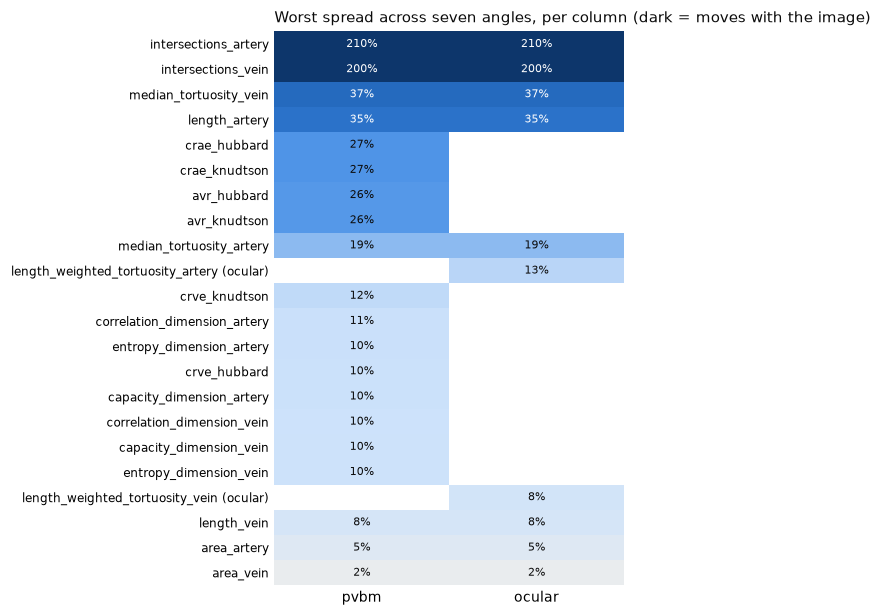

In [6]:
if len(ROTATION):
    shown = ROTATION.loc[ROTATION.max(axis=1).sort_values(ascending=False).index]
    se.heat(
        shown,
        "Worst spread across seven angles, per column (dark = moves with the image)",
        cap=0.5,
    )
    plt.show()

### 3.2 The columns with no canonical name

The same check on every unnamed column. Nothing can compare these with a definition, but they are
as capable of turning with the image as anything else, and nothing else would notice.

In [7]:
OWN_ROTATION = se.rotation(EVIDENCE, named=False, by=ROW)
if OWN_ROTATION.empty:
    print("nothing unnamed to check")
else:
    table = OWN_ROTATION.rename("worst spread").to_frame()
    moving = table[table.iloc[:, 0] > ROTATION_TOLERANCE]
    print(
        f"{len(moving)} of {len(table)} unnamed columns move by more than {ROTATION_TOLERANCE:.0%}"
    )
    display(se.legible(moving.sort_values("worst spread", ascending=False)))

16 of 18 unnamed columns move by more than 10%


worst spread
implementation native                                    
ocular         median_branching_angle_vein          67.1%
pvbm           median_branching_angle_vein          67.1%
               singularity_length_vein              61.8%
               singularity_length_artery            59.4%
               median_branching_angle_artery        47.8%
ocular         median_branching_angle_artery        47.8%
               endpoints_artery                     35.9%
               start_points_artery                  35.9%
pvbm           start_points_artery                  35.9%
               endpoints_artery                     35.9%
ocular         endpoints_vein                       25.2%
pvbm           endpoints_vein                       25.2%
               tortuosity_index_artery              14.5%
ocular         tortuosity_index_artery              14.5%
               tortuosity_index_vein                13.9%
pvbm           tortuosity_index_vein                13.9%

## 4. Agreement with ground truth, by canonical name

Every named measurement against the value the catalogue's definition requires of that shape.

### 4.1 The worst disagreement, over every shape and angle

In [8]:
EVERYWHERE = EVIDENCE.in_order(
    AGAINST.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
)
faults = se.over(EVERYWHERE, GROUND_TRUTH_TOLERANCE)
print(
    f"{len(AGAINST):,} measurements over {AGAINST[ROW].nunique()} named columns; "
    f"{len(faults)} are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere. Worst:"
)
commented(se.legible(faults.loc[faults.max(axis=1).sort_values(ascending=False).index]))

2,630 measurements over 22 named columns; 15 are out by more than 25% somewhere. Worst:


implementation,pvbm,ocular,canonical
native,,,
intersections_vein,57×,57×,topology/junctions/vein
intersections_artery,43×,43×,topology/junctions/artery
crve_hubbard,55.8%,—,calibre/CRE-hubbard/vein/B
avr_hubbard,47.0%,—,calibre/AVR-hubbard/both/B
capacity_dimension_vein,33.3%,—,density/multifractal-d0/vein
capacity_dimension_artery,32.6%,—,density/multifractal-d0/artery
crae_hubbard,30.9%,—,calibre/CRE-hubbard/artery/B
length_artery,30.8%,30.8%,density/skeleton-length-rooted/artery
crve_knudtson,30.4%,—,calibre/CRE-knudtson/vein/B


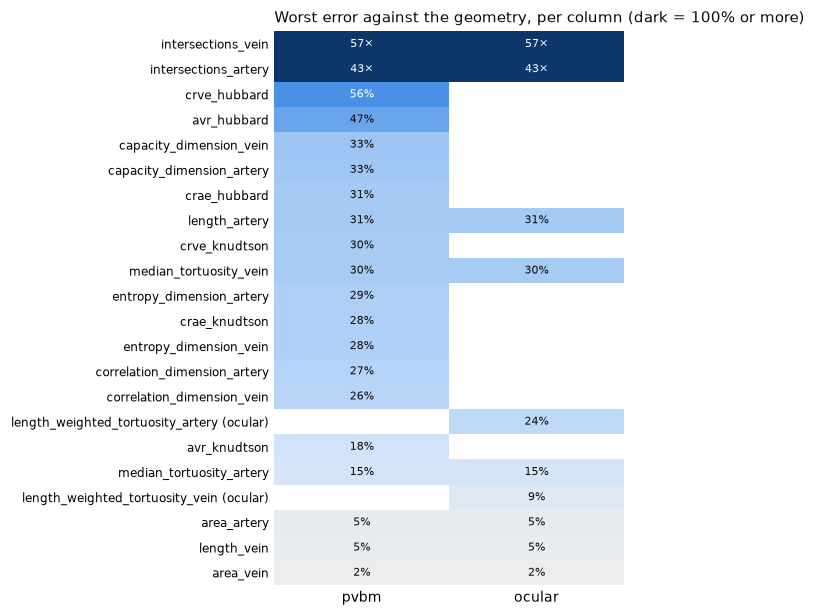

In [9]:
shown = EVERYWHERE.loc[EVERYWHERE.max(axis=1).sort_values(ascending=False).index]
se.heat(shown, "Worst error against the geometry, per column (dark = 100% or more)")
plt.show()

### 4.2 Where the errors fall

Every measurement of a biomarker that is out of tolerance somewhere, as one dot per shape and
angle, signed: right of the line the program said more than the geometry requires, left of it less.
The shaded band is the 25% tolerance. A tight cluster away from nought is a formula; a scatter is
the grid or the shape.

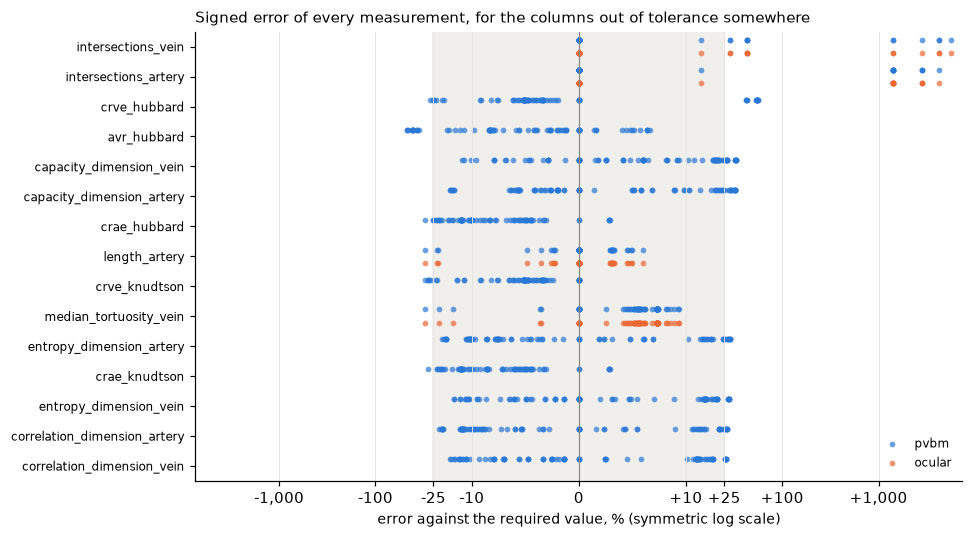

In [10]:
order = list(faults.max(axis=1).sort_values(ascending=False).index)
if order:
    se.strips(
        AGAINST[AGAINST[ROW].isin(order)],
        order,
        IMPLEMENTATIONS,
        "Signed error of every measurement, for the columns out of tolerance somewhere",
        index=ROW,
    )
    plt.show()
else:
    print("nothing is out of tolerance")

### 4.3 The same, one shape at a time

The worst over each shape's seven angles, for the biomarkers out of tolerance on that shape. A
biomarker wrong on one shape and right on the rest is a different finding from one wrong on all of
them, and §4.1 cannot tell them apart.

In [11]:
for number, shape in enumerate(EVIDENCE.shapes, start=1):
    here = AGAINST[AGAINST["shape"] == shape]
    table = se.over(
        EVIDENCE.in_order(
            here.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
        ),
        GROUND_TRUTH_TOLERANCE,
    )
    heading(f"#### 4.3.{number} {shape} — {len(table)} out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    if table.empty:
        print("every comparable biomarker lands within tolerance on this shape")
    else:
        display(commented(se.legible(table)))

#### 4.3.1 arc — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


#### 4.3.2 bifurcation — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


#### 4.3.3 clothoid — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


... (16 outputs left out)

#### 4.3.12 straight — 0 out by more than 25%

every comparable biomarker lands within tolerance on this shape


#### 4.3.13 tree — 1 out by more than 25%

implementation,pvbm,ocular,canonical
native,,,
capacity_dimension_vein,25.0%,—,density/multifractal-d0/vein


### 4.4 By how the ground truth is known

A fault against an `exact` value is a fault. One against a `convention` is a question about the
definition, against an `asymptotic` value a question about how far a finite raster can go, and
against a `numerical` one a question about a 20 µm grid. They are counted apart, never pooled.

In [12]:
by_kind = (
    AGAINST.assign(out=AGAINST["error"] > GROUND_TRUTH_TOLERANCE)
    .groupby(["kind", "implementation"])["out"]
    .agg(lambda out: f"{int(out.sum())} / {len(out)}")
    .unstack("implementation")
)
EVIDENCE.in_order(by_kind)

implementation,pvbm,ocular
kind,,
asymptotic,61 / 546,NaN
convention,7 / 394,7 / 28
exact,59 / 808,19 / 854


### 4.5 Where the geometry gives no value

A biomarker a shape settles as having **none**: no junction to take an angle at, no vessel in
zone C, no whole vessel where nothing reaches the disc. Declining there is the right answer, and a
number is invented. Each cell is how many times a number came back, out of how many it was asked.

In [13]:
INVENTED = se.invented(EVIDENCE)
if INVENTED.empty:
    print("no named column was asked about a value the geometry leaves undefined")
else:
    asked = INVENTED.groupby([ROW, "implementation"])["invented"]
    table = EVIDENCE.in_order(
        (asked.sum().astype(int).astype(str) + " / " + asked.size().astype(str)).unstack(
            "implementation"
        )
    )
    answered = INVENTED.groupby(ROW)["invented"].any()
    print(
        f"{int(INVENTED['invented'].sum())} numbers invented out of {len(INVENTED)} chances; "
        f"the biomarkers somebody answered:"
    )
    display(commented(table.loc[answered[answered].index] if answered.any() else table.head(0)))

0 numbers invented out of 42 chances; the biomarkers somebody answered:


implementation,pvbm,canonical
native,,


## 5. Agreement with their own description

The columns the catalogue cannot name, each against what **its own authors** say it computes (§1.1).
Where that claim is a quantity the catalogue does name — Hart's squared curvature, say, which a
column is named after but does not compute — the claim's value is that biomarker's ground truth;
otherwise it is derived from the geometry. This is the claim-against-observation comparison the
atlas asks every catalogued project for, made on numbers.

In [14]:
if CLAIMED.empty:
    print("no column of this group is held to a description of its own")
else:
    OWN = (
        CLAIMED.groupby(["implementation", ROW])
        .agg(
            claims=("claims", "first"),
            held_to=("as", "first"),
            worst=("error", "max"),
            median=("error", "median"),
            renderings=("error", "size"),
        )
        .sort_values("worst", ascending=False)
    )
    print(
        f"{len(OWN)} columns held to their own description; {int((OWN['worst'] > GROUND_TRUTH_TOLERANCE).sum())} "
        f"are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere (worst and median):"
    )
    display(OWN.assign(worst=OWN["worst"].map(se.readable), median=OWN["median"].map(se.readable)))

16 columns held to their own description; 10 are out by more than 25% somewhere (worst and median):


claims                                 held_to   worst median  renderings
implementation native                                                                                                                                                                   
ocular         median_branching_angle_vein               the median angle between the two daughters at a branch point    topology/branching-angle/vein/median  129.5%  13.4%          20
pvbm           median_branching_angle_vein               the median angle between the two daughters at a branch point    topology/branching-angle/vein/median  129.5%  13.4%          20
               median_branching_angle_artery             the median angle between the two daughters at a branch point  topology/branching-angle/artery/median  129.3%   7.4%          28
ocular         median_branching_angle_artery             the median angle between the two daughters at a branch point  topology/branching-angle/artery/median  129.3%   7.4%          28
pvbm           endpoints_artery                                                        how many vessel ends there are               topology/endpoints/artery  100.0%  50.0%          91
               endpoints_vein                                                          how many vessel ends there are                 topology/endpoints/vein  100.0%  50.0%          91
ocular         endpoints_vein                                                          how many vessel ends there are                 topology/endpoints/vein  100.0%  50.0%          91
               endpoints_artery                                                        how many vessel ends there are               topology/endpoints/artery  100.0%  50.0%          91
pvbm           start_points_artery                                              how many vessels leave the optic disc               derived from the geometry   33.3%   0.0%          91
ocular         start_points_artery                                              how many vessels leave the optic disc               derived from the geometry   33.3%   0.0%          91
               tortuosity_index_artery        total arc length over total chord length, over every segment of the map               derived from the geometry   15.8%   5.5%          84
pvbm           tortuosity_index_artery        total arc length over total chord length, over every segment of the map               derived from the geometry   15.8%   5.5%          84
               tortuosity_index_vein          total arc length over total chord length, over every segment of the map               derived from the geometry   10.6%   5.3%          84
ocular         tortuosity_index_vein          total arc length over total chord length, over every segment of the map               derived from the geometry   10.6%   5.3%          84
               start_points_vein                                                how many vessels leave the optic disc               derived from the geometry    0.0%   0.0%          91
pvbm           start_points_vein                                                how many vessels leave the optic disc               derived from the geometry    0.0%   0.0%          91

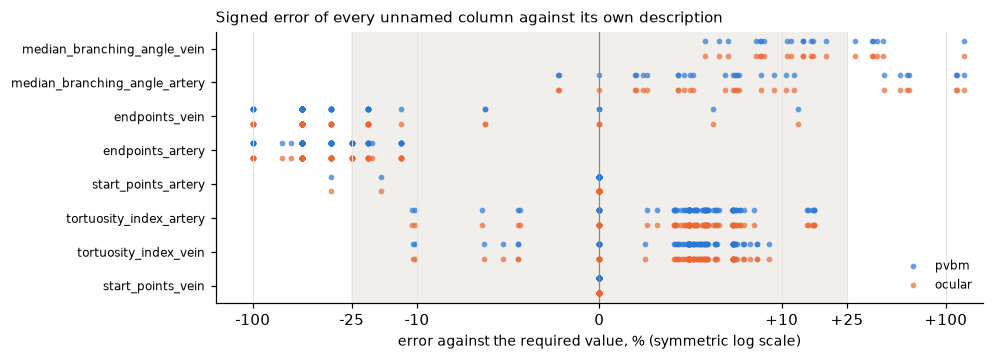

In [15]:
if not CLAIMED.empty:
    order = list(
        CLAIMED.groupby(ROW)["error"].max().sort_values(ascending=False).index
    )
    se.strips(
        CLAIMED,
        order,
        IMPLEMENTATIONS,
        "Signed error of every unnamed column against its own description",
        index=ROW,
    )
    plt.show()

## 6. The best and the worst biomarkers in this group

For each implementation, its catalogued biomarkers ordered by how close they came to the geometry,
judged by their **worst** case over every shape and angle, then by their median. *Best* lists every
biomarker inside the noise floor everywhere, and at least the closest few besides (never more than
half of what it answers). *Worst* lists, of the biomarkers out by more than 25% somewhere, the five
furthest, with the shape and angle where each was furthest.

This orders biomarkers within one program, not programs: it says which of an implementation's
numbers can be taken at face value on these shapes, and which cannot.

In [16]:
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    best, worst = se.best_and_worst(AGAINST, slug, by=ROW)
    heading(f"### 6.{number} {slug}")
    heading(f"**Best** — {len(best)} biomarker(s)")
    shown = best.copy()
    shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
    display(commented(shown))
    heading(f"**Worst** — out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere")
    if worst.empty:
        print(f"nothing it answers is out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    else:
        shown = worst.copy()
        shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
        display(commented(shown))

### 6.1 pvbm

**Best** — 5 biomarker(s)

,worst,median,renderings,worst on,canonical
native,,,,,
area_vein,1.7%,0.0%,91,spokes-disc-centred 0°,density/area/vein
length_vein,4.5%,0.0%,91,deep-bifurcation 60°,density/skeleton-length-rooted/vein
area_artery,5.0%,0.0%,91,crossing 0°,density/area/artery
median_tortuosity_artery,15.0%,6.0%,84,koch 15°,tortuosity/hart-tau1/artery/median
avr_knudtson,17.9%,4.9%,80,koch 15°,calibre/AVR-knudtson/both/B


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on,canonical
native,,,,,
intersections_vein,57×,0.0%,91,koch 90°,topology/junctions/vein
intersections_artery,43×,0.0%,91,koch 15°,topology/junctions/artery
crve_hubbard,55.8%,5.1%,84,spokes-disc-centred 45°,calibre/CRE-hubbard/vein/B
avr_hubbard,47.0%,6.1%,80,spokes-disc-centred 45°,calibre/AVR-hubbard/both/B
capacity_dimension_vein,33.3%,8.2%,91,spokes-disc-centred 0°,density/multifractal-d0/vein


### 6.2 ocular

**Best** — 5 biomarker(s)

,worst,median,renderings,worst on,canonical
native,,,,,
area_vein,1.7%,0.0%,91,spokes-disc-centred 0°,density/area/vein
length_vein,4.5%,0.0%,91,deep-bifurcation 60°,density/skeleton-length-rooted/vein
area_artery,5.0%,0.0%,91,crossing 0°,density/area/artery
length_weighted_tortuosity_vein (ocular),9.5%,5.2%,84,deep-bifurcation 75°,tortuosity/hart-tau1/vein/length-weighted
median_tortuosity_artery,15.0%,6.0%,84,koch 15°,tortuosity/hart-tau1/artery/median


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on,canonical
native,,,,,
intersections_vein,57×,0.0%,91,koch 90°,topology/junctions/vein
intersections_artery,43×,0.0%,91,koch 15°,topology/junctions/artery
length_artery,30.8%,0.0%,91,spokes-macula-centred 75°,density/skeleton-length-rooted/artery
median_tortuosity_vein,30.4%,6.1%,84,koch 90°,tortuosity/hart-tau1/vein/median


### 6.3 Across the group

The same question asked of the group as a whole: for each canonical biomarker some member
computes, the member that came closest and its worst error. A biomarker is the group's best when
some member measures it to within the floor; its worst when even the closest member is far.

In [17]:
closest = AGAINST.groupby([ROW, "implementation"])["error"].max().unstack("implementation")
GROUP_TABLE = pd.DataFrame(
    {
        # Siblings that tie are named together: PVBM and OCULAR run the same code, so picking one
        # would credit it with a result that belongs to both.
        "closest member": closest.apply(
            lambda row: " = ".join(row.index[row == row.min()]), axis=1
        ),
        "its worst error": closest.min(axis=1),
        "members answering": closest.notna().sum(axis=1),
    }
).sort_values("its worst error")
heading(
    f"**{int((GROUP_TABLE['its worst error'] == 0).sum())} of {len(GROUP_TABLE)}** named "
    f"columns are measured to within the floor by at least one member. The closest five, then the "
    f"five furthest of those out by more than {GROUND_TRUTH_TOLERANCE:.0%} even at their closest:"
)
furthest = GROUP_TABLE[GROUP_TABLE["its worst error"] > GROUND_TRUTH_TOLERANCE].tail(5).iloc[::-1]
display(
    commented(
        pd.concat({"closest": GROUP_TABLE.drop(index=furthest.index).head(5), "furthest": furthest})
        .rename_axis(["", ROW])
        .assign(**{"its worst error": lambda t: t["its worst error"].map(se.readable)})
    )
)

**0 of 22** named columns are measured to within the floor by at least one member. The closest five, then the five furthest of those out by more than 25% even at their closest:

closest member its worst error  members answering                                  canonical
         native                                                                                                                               
closest  area_vein                                 ocular = pvbm            1.7%                  2                          density/area/vein
         length_vein                               ocular = pvbm            4.5%                  2        density/skeleton-length-rooted/vein
         area_artery                               ocular = pvbm            5.0%                  2                        density/area/artery
         length_weighted_tortuosity_vein (ocular)         ocular            9.5%                  1  tortuosity/hart-tau1/vein/length-weighted
         median_tortuosity_artery                  ocular = pvbm           15.0%                  2         tortuosity/hart-tau1/artery/median
furthest intersections_vein                        ocular = pvbm             57×                  2                    topology/junctions/vein
         intersections_artery                      ocular = pvbm             43×                  2                  topology/junctions/artery
         crve_hubbard                                       pvbm           55.8%                  1                 calibre/CRE-hubbard/vein/B
         avr_hubbard                                        pvbm           47.0%                  1                 calibre/AVR-hubbard/both/B
         capacity_dimension_vein                            pvbm           33.3%                  1               density/multifractal-d0/vein

## 7. Summary

Two counts per implementation, each as a fraction so its denominator is visible. Rotation can be
checked on anything that returned a number; agreement only on what has a value to agree with, by
canonical name or by its own description.

In [18]:
EVERY_ROTATION = pd.concat([se.rotation(EVIDENCE, True), se.rotation(EVIDENCE, False)])
summary = {}
for slug in IMPLEMENTATIONS:
    steady = EVERY_ROTATION.loc[slug].dropna() if slug in EVERY_ROTATION.index.get_level_values(0) else pd.Series(dtype=float)
    named = AGAINST[AGAINST["implementation"] == slug].groupby(ROW)["error"].max()
    own = CLAIMED[CLAIMED["implementation"] == slug].groupby("own")["error"].max()
    summary[slug] = {
        "move with the image": f"{int((steady > ROTATION_TOLERANCE).sum())} / {len(steady)}",
        "disagree with the geometry (canonical)": f"{int((named > GROUND_TRUTH_TOLERANCE).sum())} / {len(named)}",
        "disagree with their own description": f"{int((own > GROUND_TRUTH_TOLERANCE).sum())} / {len(own)}",
        "median error, canonical": f"{100 * AGAINST.loc[AGAINST['implementation'] == slug, 'error'].median():.1f}%",
        "exceptions": int((TROUBLES["implementation"] == slug).sum()),
        "seconds per image": round(EVIDENCE.measured[slug]["seconds"].astype(float).mean(), 1),
    }
pd.DataFrame(summary)

,pvbm,ocular
move with the image,24 / 30,13 / 18
disagree with the geometry (canonical),15 / 20,4 / 10
disagree with their own description,5 / 8,5 / 8
"median error, canonical",4.9%,0.0%
exceptions,0,0
seconds per image,64.9,4.8


## 8. What this group's evidence shows

*Our reading of the tables above, on the run of 2026-11-22. Every figure is one this notebook
printed; the authors' own claims are in §1.1 and are not restated as ours.*

**PVBM and OCULAR return the same number wherever they share a column**, because OCULAR runs PVBM's
code. Their agreement is evidence about that code, not two confirmations. What separates them is
scope and cost: PVBM adds the central retinal equivalents, the AVR and the multifractal dimensions,
and takes 64.9 s an image; OCULAR adds a length-weighted tortuosity, at 4.8 s.

**Area and length are where this lineage is trustworthy.** Vessel area is within 1.7% (veins) and
5.0% (arteries) everywhere; rooted skeleton length of veins within 4.5%. The median OCULAR error over
every judged measurement is 0.0% and PVBM's 4.9%.

**Junction counts are where it fails.** On the Koch curve, a single unbranched vessel, both report 3
or 4 junctions where there are none — the short spurs a skeleton leaves at a 60° corner — and the
count moves by 200–210% as the picture turns.

**PVBM's central retinal equivalents carry the documented unit problem.** Hubbard's venular
equivalent is 55.8% out and the Hubbard AVR 47.0% on the spoke shapes built to settle them,
consistent with Hubbard's micron constants applied to pixel widths. Knudtson's equivalents, which
are scale-free, are 28.5–30.4% out at worst, on `deep-bifurcation`. All of them move by 10–27% under
rotation.

**Held to their own description:**

- The tortuosity index, a ratio of total arc length to total chord length, is within 15.8% at
  worst and 5.5% at the median. This supports the corrected reading of PVBM's index (a ratio of
  sums, not length-weighted).
- The endpoint count leaves out the end at the disc: 1 on a straight vessel with two ends, 2 on
  a bifurcation with three, 6 on six spokes with twelve, and 0 on vessels that never reach the
  disc. It counts the free tips of vessels rooted at the disc, not every end. That is a
  definition, and not the one the column's name suggests.
- The median branching angle is 80° where the daughters part at 50° on `deep-bifurcation`, the
  pairwise-angle behaviour already recorded on the topology page.

**Which to reach for, within this lineage:** OCULAR for anything the two share, since it is the same
number thirteen times faster; PVBM only for what OCULAR lacks, and Knudtson's equivalents rather
than Hubbard's.